In [3]:
!pip install requests beautifulsoup4 pandas matplotlib -q

import requests
from bs4 import BeautifulSoup
import pandas as pd
import sqlite3
import time
import matplotlib.pyplot as plt

print("تمام، كله جاهز ✅")

تمام، كله جاهز ✅


In [4]:
url = "https://books.toscrape.com/catalogue/page-1.html"

response = requests.get(url)
response.encoding = "utf-8"   # عشان رمز الجنيه £ يظهر صح

print("كود الاستجابة:", response.status_code)

soup = BeautifulSoup(response.text, "html.parser")

# كل كتاب موجود جوه وسم article بالكلاس product_pod
books = soup.find_all("article", class_="product_pod")
print("عدد الكتب في الصفحة:", len(books))

كود الاستجابة: 200
عدد الكتب في الصفحة: 20


In [5]:
first_book = books[0]
print(first_book.prettify())

<article class="product_pod">
 <div class="image_container">
  <a href="a-light-in-the-attic_1000/index.html">
   <img alt="A Light in the Attic" class="thumbnail" src="../media/cache/2c/da/2cdad67c44b002e7ead0cc35693c0e8b.jpg"/>
  </a>
 </div>
 <p class="star-rating Three">
  <i class="icon-star">
  </i>
  <i class="icon-star">
  </i>
  <i class="icon-star">
  </i>
  <i class="icon-star">
  </i>
  <i class="icon-star">
  </i>
 </p>
 <h3>
  <a href="a-light-in-the-attic_1000/index.html" title="A Light in the Attic">
   A Light in the ...
  </a>
 </h3>
 <div class="product_price">
  <p class="price_color">
   £51.77
  </p>
  <p class="instock availability">
   <i class="icon-ok">
   </i>
   In stock
  </p>
  <form>
   <button class="btn btn-primary btn-block" data-loading-text="Adding..." type="submit">
    Add to basket
   </button>
  </form>
 </div>
</article>



In [6]:
title = first_book.h3.a["title"]
price = first_book.find("p", class_="price_color").text
rating = first_book.find("p", class_="star-rating")["class"][1]
availability = first_book.find("p", class_="instock").text.strip()

print("العنوان:", title)
print("السعر:", price)
print("التقييم:", rating)
print("التوفر:", availability)

العنوان: A Light in the Attic
السعر: £51.77
التقييم: Three
التوفر: In stock


In [7]:
RATING_MAP = {"One": 1, "Two": 2, "Three": 3, "Four": 4, "Five": 5}

def parse_book(book):
    """تاخد وسم article وترجع dictionary ببيانات الكتاب"""
    title = book.h3.a["title"]
    price = float(book.find("p", class_="price_color").text.replace("£", "").replace("Â", "").strip())
    rating = RATING_MAP[book.find("p", class_="star-rating")["class"][1]]
    in_stock = "In stock" in book.find("p", class_="instock").text
    link = book.h3.a["href"]
    return {
        "title": title,
        "price_gbp": price,
        "rating": rating,
        "in_stock": in_stock,
        "link": link,
    }

In [8]:
all_books = []
base_url = "https://books.toscrape.com/catalogue/page-{}.html"

for page in range(1, 51):
    url = base_url.format(page)
    try:
        response = requests.get(url, timeout=10)
        response.encoding = "utf-8"

        if response.status_code != 200:
            print(f"صفحة {page}: فشلت (كود {response.status_code})")
            continue

        soup = BeautifulSoup(response.text, "html.parser")
        books = soup.find_all("article", class_="product_pod")

        for book in books:
            all_books.append(parse_book(book))

        print(f"صفحة {page}: تم سحب {len(books)} كتاب | الإجمالي: {len(all_books)}")
        time.sleep(0.5)   # نهدّي شوية عشان منضغطش على السيرفر

    except Exception as e:
        print(f"صفحة {page}: خطأ -> {e}")

print("\nخلصنا ✅ إجمالي الكتب:", len(all_books))

صفحة 1: تم سحب 20 كتاب | الإجمالي: 20
صفحة 2: تم سحب 20 كتاب | الإجمالي: 40
صفحة 3: تم سحب 20 كتاب | الإجمالي: 60
صفحة 4: تم سحب 20 كتاب | الإجمالي: 80
صفحة 5: تم سحب 20 كتاب | الإجمالي: 100
صفحة 6: تم سحب 20 كتاب | الإجمالي: 120
صفحة 7: تم سحب 20 كتاب | الإجمالي: 140
صفحة 8: تم سحب 20 كتاب | الإجمالي: 160
صفحة 9: تم سحب 20 كتاب | الإجمالي: 180
صفحة 10: تم سحب 20 كتاب | الإجمالي: 200
صفحة 11: تم سحب 20 كتاب | الإجمالي: 220
صفحة 12: تم سحب 20 كتاب | الإجمالي: 240
صفحة 13: تم سحب 20 كتاب | الإجمالي: 260
صفحة 14: تم سحب 20 كتاب | الإجمالي: 280
صفحة 15: تم سحب 20 كتاب | الإجمالي: 300
صفحة 16: تم سحب 20 كتاب | الإجمالي: 320
صفحة 17: تم سحب 20 كتاب | الإجمالي: 340
صفحة 18: تم سحب 20 كتاب | الإجمالي: 360
صفحة 19: تم سحب 20 كتاب | الإجمالي: 380
صفحة 20: تم سحب 20 كتاب | الإجمالي: 400
صفحة 21: تم سحب 20 كتاب | الإجمالي: 420
صفحة 22: تم سحب 20 كتاب | الإجمالي: 440
صفحة 23: تم سحب 20 كتاب | الإجمالي: 460
صفحة 24: تم سحب 20 كتاب | الإجمالي: 480
صفحة 25: تم سحب 20 كتاب | الإجمالي: 500
صفحة 26: تم س

In [13]:
df = pd.DataFrame(all_books)
print(df.shape)
df.head()

(1000, 5)


,title,price_gbp,rating,in_stock,link
0,A Light in the Attic,51.77,3,True,a-light-in-the-attic_1000/index.html
1,Tipping the Velvet,53.74,1,True,tipping-the-velvet_999/index.html
2,Soumission,50.10,1,True,soumission_998/index.html
3,Sharp Objects,47.82,4,True,sharp-objects_997/index.html
4,Sapiens: A Brief History of Humankind,54.23,5,True,sapiens-a-brief-history-of-humankind_996/index...


In [14]:
print("الأبعاد:", df.shape)
print("\nأنواع الأعمدة:")
print(df.dtypes)

print("\nقيم فاضية في كل عمود:")
print(df.isnull().sum())

print("\nكتب مكررة (نفس العنوان):", df.duplicated(subset="title").sum())
print("روابط مكررة:", df.duplicated(subset="link").sum())

الأبعاد: (1000, 5)

أنواع الأعمدة:
title         object
price_gbp    float64
rating         int64
in_stock        bool
link          object
dtype: object

قيم فاضية في كل عمود:
title        0
price_gbp    0
rating       0
in_stock     0
link         0
dtype: int64

كتب مكررة (نفس العنوان): 1
روابط مكررة: 0


In [15]:
print(df["price_gbp"].describe())

print("\nتوزيع التقييمات:")
print(df["rating"].value_counts().sort_index())

print("\nمتاح / غير متاح:")
print(df["in_stock"].value_counts())

count    1000.00000
mean       35.07035
std        14.44669
min        10.00000
25%        22.10750
50%        35.98000
75%        47.45750
max        59.99000
Name: price_gbp, dtype: float64

توزيع التقييمات:
rating
1    226
2    196
3    203
4    179
5    196
Name: count, dtype: int64

متاح / غير متاح:
in_stock
True    1000
Name: count, dtype: int64


In [16]:
# 1) نشيل المكرر لو موجود (على أساس الرابط)
df = df.drop_duplicates(subset="link").reset_index(drop=True)

# 2) نعمل رابط كامل للكتاب
df["url"] = "https://books.toscrape.com/catalogue/" + df["link"]
df = df.drop(columns="link")

# 3) عمود فئة السعر (رخيص / متوسط / غالي)
df["price_tier"] = pd.cut(
    df["price_gbp"],
    bins=[0, 20, 40, 100],
    labels=["رخيص", "متوسط", "غالي"]
)

# 4) نعمل id لكل كتاب
df.insert(0, "book_id", range(1, len(df) + 1))

print(df.shape)
df.head()

(1000, 7)


,book_id,title,price_gbp,rating,in_stock,url,price_tier
0,1,A Light in the Attic,51.77,3,True,https://books.toscrape.com/catalogue/a-light-i...,غالي
1,2,Tipping the Velvet,53.74,1,True,https://books.toscrape.com/catalogue/tipping-t...,غالي
2,3,Soumission,50.10,1,True,https://books.toscrape.com/catalogue/soumissio...,غالي
3,4,Sharp Objects,47.82,4,True,https://books.toscrape.com/catalogue/sharp-obj...,غالي
4,5,Sapiens: A Brief History of Humankind,54.23,5,True,https://books.toscrape.com/catalogue/sapiens-a...,غالي


In [17]:
conn = sqlite3.connect("books.db")
df.to_sql("books", conn, if_exists="replace", index=False)
print("تم التخزين ✅")

تم التخزين ✅


In [18]:
print(pd.read_sql("SELECT COUNT(*) AS total_books FROM books", conn))

   total_books
0         1000


In [19]:
q1 = """
SELECT title, price_gbp, rating
FROM books
ORDER BY price_gbp DESC
LIMIT 5
"""
print(pd.read_sql(q1, conn))

                                title  price_gbp  rating
0  The Perfect Play (Play by Play #1)      59.99       3
1   Last One Home (New Beginnings #1)      59.98       3
2    Civilization and Its Discontents      59.95       2
3      The Barefoot Contessa Cookbook      59.92       5
4           The Diary of a Young Girl      59.90       3


In [20]:
q2 = """
SELECT rating,
       COUNT(*) AS books_count,
       ROUND(AVG(price_gbp), 2) AS avg_price
FROM books
GROUP BY rating
ORDER BY rating DESC
"""
print(pd.read_sql(q2, conn))

   rating  books_count  avg_price
0       5          196      35.37
1       4          179      36.09
2       3          203      34.69
3       2          196      34.81
4       1          226      34.56


In [21]:
q3 = """
SELECT title, price_gbp
FROM books
WHERE rating = 5
  AND price_gbp < 20
  AND in_stock = 1
ORDER BY price_gbp
"""
print(pd.read_sql(q3, conn))

                                                title  price_gbp
0                          An Abundance of Katherines      10.00
1                                Greek Mythic History      10.23
2   The Power Greens Cookbook: 140 Delicious Super...      11.05
3                                  Dear Mr. Knightley      11.21
4                                 The Darkest Corners      11.33
5   Naturally Lean: 125 Nourishing Gluten-Free, Pl...      11.38
6            Fruits Basket, Vol. 2 (Fruits Basket #2)      11.64
7               Old School (Diary of a Wimpy Kid #10)      11.83
8   Superman Vol. 1: Before Truth (Superman by Gen...      11.89
9    Every Heart a Doorway (Every Heart A Doorway #1)      12.16
10                                  The Girl You Lost      12.29
11                                    The Silent Wife      12.34
12                     Agnostic: A Spirited Manifesto      12.51
13  The Third Wave: An Entrepreneur’s Vision of th...      12.61
14                  Walt 

In [22]:
home = requests.get("https://books.toscrape.com/index.html", timeout=10)
home.encoding = "utf-8"
home_soup = BeautifulSoup(home.text, "html.parser")

# الأقسام في القائمة الجانبية
side = home_soup.find("div", class_="side_categories")
cat_links = side.find("ul").find("ul").find_all("a")

categories = []
for a in cat_links:
    name = a.text.strip()
    href = a["href"]   # مثال: catalogue/category/books/travel_2/index.html
    categories.append({"category": name, "href": href})

print("عدد الأقسام:", len(categories))
print(categories[:3])

عدد الأقسام: 50
[{'category': 'Travel', 'href': 'catalogue/category/books/travel_2/index.html'}, {'category': 'Mystery', 'href': 'catalogue/category/books/mystery_3/index.html'}, {'category': 'Historical Fiction', 'href': 'catalogue/category/books/historical-fiction_4/index.html'}]


In [23]:
from urllib.parse import urljoin

book_category = []   # (رابط الكتاب, القسم)

for cat in categories:
    page_url = urljoin("https://books.toscrape.com/", cat["href"])

    while page_url:
        r = requests.get(page_url, timeout=10)
        r.encoding = "utf-8"
        s = BeautifulSoup(r.text, "html.parser")

        for article in s.find_all("article", class_="product_pod"):
            # نحول الرابط لنفس الشكل المخزن في عمود url
            full = urljoin(page_url, article.h3.a["href"])
            book_category.append({"url": full, "category": cat["category"]})

        nxt = s.find("li", class_="next")
        page_url = urljoin(page_url, nxt.a["href"]) if nxt else None
        time.sleep(0.3)

    print(f"تم: {cat['category']}")

cat_df = pd.DataFrame(book_category)
print("\nإجمالي:", cat_df.shape)
cat_df.head()

تم: Travel
تم: Mystery
تم: Historical Fiction
تم: Sequential Art
تم: Classics
تم: Philosophy
تم: Romance
تم: Womens Fiction
تم: Fiction
تم: Childrens
تم: Religion
تم: Nonfiction
تم: Music
تم: Default
تم: Science Fiction
تم: Sports and Games
تم: Add a comment
تم: Fantasy
تم: New Adult
تم: Young Adult
تم: Science
تم: Poetry
تم: Paranormal
تم: Art
تم: Psychology
تم: Autobiography
تم: Parenting
تم: Adult Fiction
تم: Humor
تم: Horror
تم: History
تم: Food and Drink
تم: Christian Fiction
تم: Business
تم: Biography
تم: Thriller
تم: Contemporary
تم: Spirituality
تم: Academic
تم: Self Help
تم: Historical
تم: Christian
تم: Suspense
تم: Short Stories
تم: Novels
تم: Health
تم: Politics
تم: Cultural
تم: Erotica
تم: Crime

إجمالي: (1000, 2)


,url,category
0,https://books.toscrape.com/catalogue/its-only-...,Travel
1,https://books.toscrape.com/catalogue/full-moon...,Travel
2,https://books.toscrape.com/catalogue/see-ameri...,Travel
3,https://books.toscrape.com/catalogue/vagabondi...,Travel
4,https://books.toscrape.com/catalogue/under-the...,Travel


In [24]:
print(df["url"].iloc[0])
print(cat_df["url"].iloc[0])

https://books.toscrape.com/catalogue/a-light-in-the-attic_1000/index.html
https://books.toscrape.com/catalogue/its-only-the-himalayas_981/index.html


In [25]:
print("روابط في df:", df["url"].nunique())
print("روابط في cat_df:", cat_df["url"].nunique())

# كام رابط من df موجود في cat_df؟
matched = df["url"].isin(cat_df["url"]).sum()
print("المتطابق:", matched)

روابط في df: 1000
روابط في cat_df: 1000
المتطابق: 1000


In [26]:
cat_df = cat_df.drop_duplicates(subset="url")
cat_df.to_sql("book_categories", conn, if_exists="replace", index=False)

print(pd.read_sql("SELECT COUNT(*) AS total FROM book_categories", conn))

   total
0   1000


In [27]:
q = """
SELECT b.title, b.price_gbp, b.rating, c.category
FROM books b
JOIN book_categories c ON b.url = c.url
LIMIT 10
"""
print(pd.read_sql(q, conn))

                                               title  price_gbp  rating  \
0                               A Light in the Attic      51.77       3   
1                                 Tipping the Velvet      53.74       1   
2                                         Soumission      50.10       1   
3                                      Sharp Objects      47.82       4   
4              Sapiens: A Brief History of Humankind      54.23       5   
5                                    The Requiem Red      22.65       1   
6  The Dirty Little Secrets of Getting Your Dream...      33.34       4   
7  The Coming Woman: A Novel Based on the Life of...      17.93       3   
8  The Boys in the Boat: Nine Americans and Their...      22.60       4   
9                                    The Black Maria      52.15       1   

             category  
0              Poetry  
1  Historical Fiction  
2             Fiction  
3             Mystery  
4             History  
5         Young Adult  
6     

In [28]:
q1 = """
SELECT c.category, COUNT(*) AS books_count
FROM books b
JOIN book_categories c ON b.url = c.url
GROUP BY c.category
ORDER BY books_count DESC
LIMIT 10
"""
print(pd.read_sql(q1, conn))

         category  books_count
0         Default          152
1      Nonfiction          110
2  Sequential Art           75
3   Add a comment           67
4         Fiction           65
5     Young Adult           54
6         Fantasy           48
7         Romance           35
8         Mystery           32
9  Food and Drink           30


In [29]:
q2 = """
SELECT c.category,
       COUNT(*) AS books_count,
       ROUND(AVG(b.price_gbp), 2) AS avg_price
FROM books b
JOIN book_categories c ON b.url = c.url
GROUP BY c.category
HAVING COUNT(*) >= 5
ORDER BY avg_price DESC
LIMIT 10
"""
print(pd.read_sql(q2, conn))

           category  books_count  avg_price
0         New Adult            6      46.38
1  Sports and Games            5      41.17
2         Self Help            5      40.62
3            Travel           11      39.79
4           Fantasy           48      39.59
5               Art            8      38.52
6           History           18      37.29
7     Autobiography            9      37.05
8    Womens Fiction           17      36.79
9          Classics           19      36.55


In [30]:
q3 = """
SELECT c.category,
       COUNT(*) AS books_count,
       ROUND(AVG(b.rating), 2) AS avg_rating
FROM books b
JOIN book_categories c ON b.url = c.url
GROUP BY c.category
HAVING COUNT(*) >= 5
ORDER BY avg_rating DESC
LIMIT 10
"""
print(pd.read_sql(q3, conn))

             category  books_count  avg_rating
0   Christian Fiction            6        4.17
1                 Art            8        3.63
2              Poetry           19        3.53
3               Humor           10        3.40
4        Spirituality            6        3.33
5         Young Adult           54        3.30
6  Historical Fiction           26        3.23
7             Fiction           65        3.18
8           New Adult            6        3.17
9               Music           13        3.15


In [31]:
q4 = """
SELECT category, title, price_gbp
FROM (
    SELECT c.category, b.title, b.price_gbp,
           ROW_NUMBER() OVER (
               PARTITION BY c.category
               ORDER BY b.price_gbp
           ) AS rn
    FROM books b
    JOIN book_categories c ON b.url = c.url
    WHERE b.rating = 5
)
WHERE rn = 1
ORDER BY price_gbp
LIMIT 10
"""
print(pd.read_sql(q4, conn))

         category                                              title  \
0     Young Adult                         An Abundance of Katherines   
1         Default                               Greek Mythic History   
2  Food and Drink  The Power Greens Cookbook: 140 Delicious Super...   
3         Fiction                                 Dear Mr. Knightley   
4  Sequential Art           Fruits Basket, Vol. 2 (Fruits Basket #2)   
5           Humor              Old School (Diary of a Wimpy Kid #10)   
6         Fantasy   Every Heart a Doorway (Every Heart A Doorway #1)   
7         Mystery                                  The Girl You Lost   
8      Nonfiction                     Agnostic: A Spirited Manifesto   
9        Business  The Third Wave: An Entrepreneur’s Vision of th...   

   price_gbp  
0      10.00  
1      10.23  
2      11.05  
3      11.21  
4      11.64  
5      11.83  
6      12.16  
7      12.29  
8      12.51  
9      12.61  


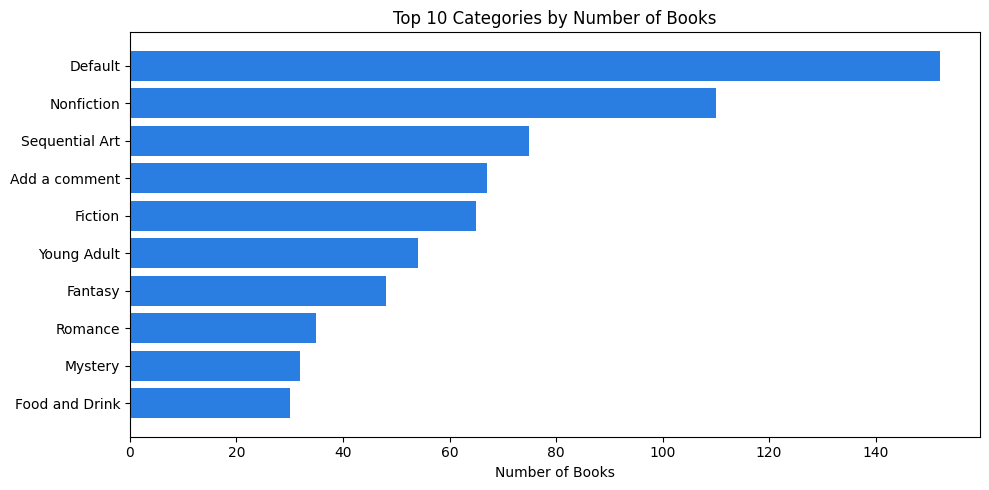

In [32]:
q = """
SELECT c.category, COUNT(*) AS books_count
FROM books b
JOIN book_categories c ON b.url = c.url
GROUP BY c.category
ORDER BY books_count DESC
LIMIT 10
"""
top_cat = pd.read_sql(q, conn)

plt.figure(figsize=(10, 5))
plt.barh(top_cat["category"][::-1], top_cat["books_count"][::-1], color="#2a7de1")
plt.title("Top 10 Categories by Number of Books")
plt.xlabel("Number of Books")
plt.tight_layout()
plt.savefig("top_categories.png", dpi=150)
plt.show()

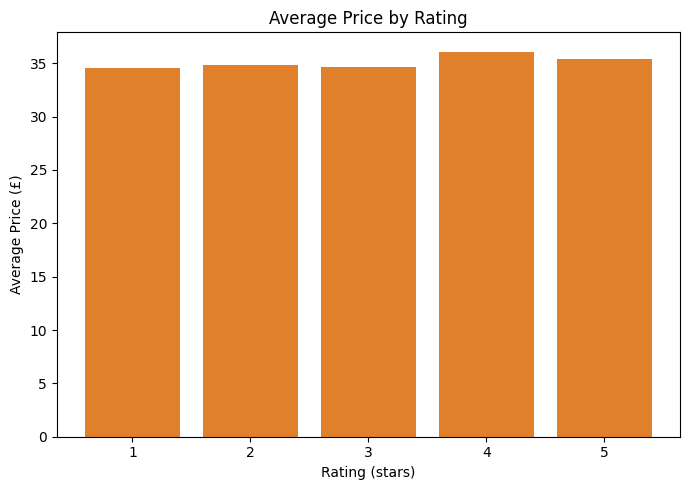

In [33]:
q = """
SELECT rating, ROUND(AVG(price_gbp), 2) AS avg_price
FROM books
GROUP BY rating
ORDER BY rating
"""
rating_price = pd.read_sql(q, conn)

plt.figure(figsize=(7, 5))
plt.bar(rating_price["rating"], rating_price["avg_price"], color="#e1802a")
plt.title("Average Price by Rating")
plt.xlabel("Rating (stars)")
plt.ylabel("Average Price (£)")
plt.tight_layout()
plt.savefig("price_by_rating.png", dpi=150)
plt.show()

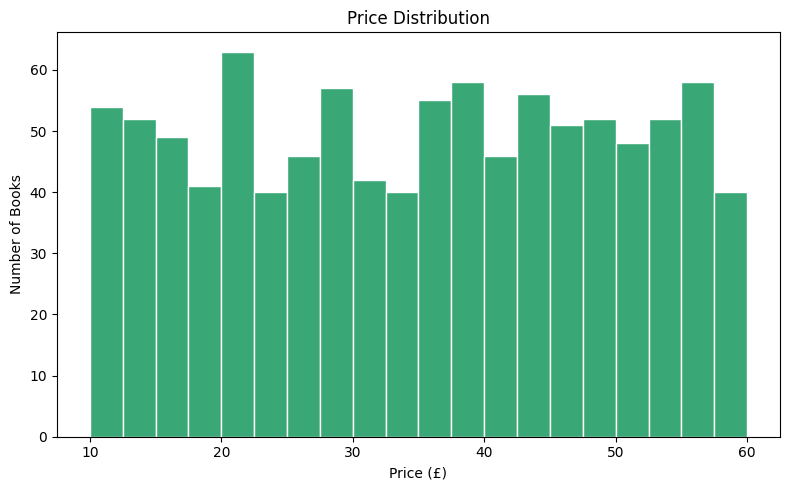

In [34]:
plt.figure(figsize=(8, 5))
plt.hist(df["price_gbp"], bins=20, color="#3aa876", edgecolor="white")
plt.title("Price Distribution")
plt.xlabel("Price (£)")
plt.ylabel("Number of Books")
plt.tight_layout()
plt.savefig("price_distribution.png", dpi=150)
plt.show()

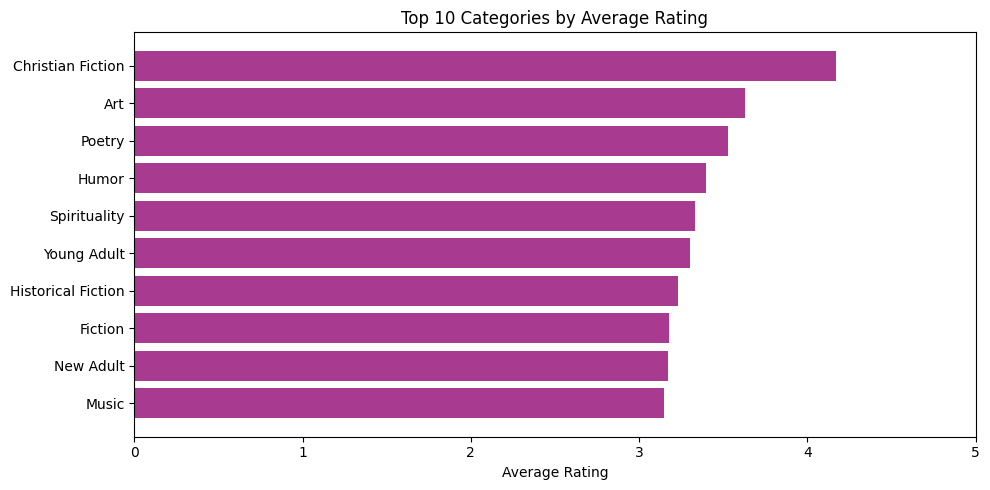

In [41]:
q = """
SELECT c.category, ROUND(AVG(b.rating), 2) AS avg_rating
FROM books b
JOIN book_categories c ON b.url = c.url
GROUP BY c.category
HAVING COUNT(*) >= 5
ORDER BY avg_rating DESC
LIMIT 10
"""
top_rating = pd.read_sql(q, conn)

plt.figure(figsize=(10, 5))
plt.barh(top_rating["category"][::-1], top_rating["avg_rating"][::-1], color="#a83a8f")
plt.title("Top 10 Categories by Average Rating")
plt.xlabel("Average Rating")
plt.xlim(0, 5)
plt.tight_layout()
plt.savefig("top_rating_categories.png", dpi=150)
plt.show()

In [42]:
readme = """# Books Price & Category Analysis

An end-to-end data project: web scraping, SQL database design, and data analysis.

## Overview
Scraped 1,000 books from [books.toscrape.com](https://books.toscrape.com) (a practice site built for scraping),
stored them in a relational SQLite database, and analyzed pricing, ratings, and categories using SQL and Python.

## Tools
- **Python**: requests, BeautifulSoup, pandas, matplotlib
- **SQL**: SQLite (JOIN, GROUP BY, HAVING, window functions)
- **Google Colab** for development

## Pipeline
1. Scraped 50 listing pages (title, price, rating, availability, URL)
2. Scraped 50 category pages to map each book to its category
3. Cleaned data with pandas (types, duplicates, price tiers)
4. Stored in SQLite as two tables: `books` and `book_categories`
5. Joined tables and ran analytical SQL queries
6. Visualized results with matplotlib

## Database Schema
- `books` (book_id, title, price_gbp, rating, in_stock, url, price_tier)
- `book_categories` (url, category)

## Key Findings
- The dataset contains 1,000 books spread across 50 categories, joined from two scraped sources into a clean relational structure.
- Price and rating show almost no relationship: paying more does not mean getting a better-rated book.
- Category size varies widely, with a few large categories holding many books while many others hold only a handful.
- Average price and average rating differ from one category to another, so category is a more useful lens than price when comparing books.

## Files
- `books_final.csv`: final cleaned dataset
- `books.db`: SQLite database
- `*.png`: charts

## How to Run
Open the notebook in Google Colab and run all cells in order.
"""

with open("README.md", "w", encoding="utf-8") as f:
    f.write(readme)

from google.colab import files
files.download("README.md")
print("تم ✅")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

تم ✅
